# 02 - Modeling
**Tujuan:** membangun pipeline preprocessing dan membandingkan model klasifikasi multiclass menggunakan Macro F1-Score.

## Daftar isi
1. Setup  
2. Load data & split X–y  
3. Pipeline preprocessing  
4. Baseline: Logistic Regression (OvR vs OvO)  
5. Random Forest  
6. LightGBM  
7. Perbandingan model  
8. Tuning hyperparameter  
9. Penanganan imbalance (threshold)  
10. Model final

In [1]:
## 1. Setup
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")   # root repo ditambahkan ke path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

from scripts.config import *
print("Config terbaca | Train ada:", TRAIN_PATH.exists())

Config terbaca | Train ada: True


In [2]:
## 2. Load Data & Split X–y
# Load data dan split X–y
from scripts.preprocess import load_data, split_xy, InvalidValueReplacer
from scripts.feature_engineering import FeatureEngineer

train = load_data(TRAIN_PATH)
X, y = split_xy(train)

# Uji transformer
X_cek = FeatureEngineer().fit_transform(InvalidValueReplacer().fit_transform(X))
print("X:", X.shape, "| y:", y.shape)
print("Kolom baru:", X_cek.shape[1] - X.shape[1])
print("NaN age/height:", X_cek["age_building"].isna().sum(), X_cek["height_ft_pre_eq"].isna().sum())
X_cek[["height_per_floor", "rc_count"]].describe().round(2)

X: (533465, 15) | y: (533465,)
Kolom baru: 2
NaN age/height: 2198 212


,height_per_floor,rc_count
count,533253.00,533465.00
mean,7.89,0.27
std,1.94,0.92
min,1.00,0.00
25%,6.50,0.00
50%,7.50,0.00
75%,9.00,0.00
max,93.00,5.00


**Catatan:** X terdiri dari 15 fitur; setelah transformer diterapkan, 2 fitur baru (`height_per_floor`, `rc_count`) ditambahkan. Nilai tidak valid berhasil diubah menjadi NaN (2.198 pada `age_building`, 212 pada `height_ft_pre_eq`).

## 3. Pipeline Preprocessing
Dua versi preprocessor disiapkan: `linear` (imputasi, log1p, scaling, one-hot) untuk Logistic Regression dan `tree` (imputasi, ordinal encoding) untuk model berbasis pohon. Kolom `vdcmun_id` dan `ward_id` pada kedua versi diencode dengan TargetEncoder (cross-fitting).

In [3]:
## 3. Pipeline Preprocessing
# Visualisasi struktur pipeline
from sklearn import set_config
from sklearn.linear_model import LogisticRegression
from scripts.train import build_pipeline

set_config(display="diagram")
build_pipeline(LogisticRegression(), kind="linear")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('replace', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,invalid_values,None
,rc_cols,None
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_num', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_thres

In [4]:
# Uji preprocessing pada sampel 20.000 baris
X_s = X.sample(20000, random_state=RANDOM_STATE)
y_s = y.loc[X_s.index]

for kind in ["linear", "tree"]:
    pipe = build_pipeline("passthrough", kind=kind)
    hasil = pipe.fit_transform(X_s, y_s)
    print(f"{kind:6} | shape: {hasil.shape} | NaN: {np.isnan(hasil).sum()}")

nama_fitur = pipe.named_steps["preprocess"].get_feature_names_out()
nama_fitur[:10]

linear | shape: (20000, 68) | NaN: 0
tree   | shape: (20000, 25) | NaN: 0


array(['num__count_floors_pre_eq', 'num__age_building',
       'num__plinth_area_sq_ft', 'num__height_ft_pre_eq',
       'num__height_per_floor', 'num__rc_count',
       'cat__land_surface_condition', 'cat__foundation_type',
       'cat__roof_type', 'cat__ground_floor_type'], dtype=object)

**Catatan:** preprocessing berjalan tanpa nilai NaN tersisa. Versi `linear` menghasilkan 68 fitur (numerik terstandardisasi, one-hot, target encoding), sedangkan versi `tree` menghasilkan 25 fitur (numerik, ordinal, district, target encoding).

In [5]:
# Split holdout train–validasi (stratified)
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Latih   :", X_tr.shape)
print("Validasi:", X_val.shape)
pd.concat({"latih": y_tr.value_counts(normalize=True), "validasi": y_val.value_counts(normalize=True)},
          axis=1).sort_index().round(3)

Latih   : (426772, 15)
Validasi: (106693, 15)


,latih,validasi
damage_grade,,
1,0.103,0.103
2,0.114,0.114
3,0.179,0.179
4,0.241,0.241
5,0.362,0.362


## 4. Baseline: Logistic Regression (OvR vs OvO)
Logistic Regression digunakan sebagai baseline dengan dua strategi multiclass: One-vs-Rest (5 classifier biner) dan One-vs-One (10 classifier biner). `class_weight="balanced"` diterapkan untuk menangani imbalance.

In [6]:
# Persiapan evaluasi
import time
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from scripts.evaluate import evaluate_model

hasil_model = []   # skor seluruh model dikumpulkan untuk perbandingan
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)

Waktu: 67 detik
LogReg OvR | Macro F1: 0.5050 | Akurasi: 0.5441

              precision    recall  f1-score   support

           1      0.526     0.754     0.620     11034
           2      0.321     0.322     0.322     12216
           3      0.395     0.386     0.391     19098
           4      0.491     0.471     0.481     25738
           5      0.747     0.681     0.712     38607

    accuracy                          0.544    106693
   macro avg      0.496     0.523     0.505    106693
weighted avg      0.550     0.544     0.545    106693



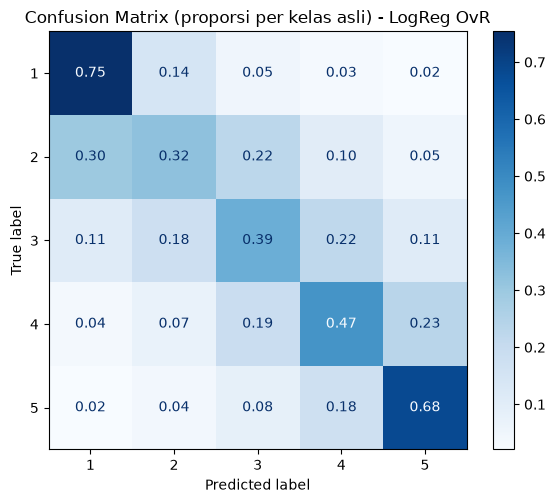

In [14]:
# Logistic Regression One-vs-Rest
pipe_ovr = build_pipeline(OneVsRestClassifier(logreg, n_jobs=-1), kind="linear")

mulai = time.time()
pipe_ovr.fit(X_tr, y_tr)
pred_ovr = pipe_ovr.predict(X_val)
print(f"Waktu: {time.time() - mulai:.0f} detik")

hasil_model.append(evaluate_model(y_val, pred_ovr, "LogReg OvR",
                                  FIGURE_DIR / "cm_logreg_ovr.png"))

Waktu: 27 detik
LogReg OvO | Macro F1: 0.5088 | Akurasi: 0.5408

              precision    recall  f1-score   support

           1      0.550     0.728     0.626     11034
           2      0.315     0.369     0.340     12216
           3      0.389     0.390     0.390     19098
           4      0.486     0.479     0.482     25738
           5      0.762     0.658     0.706     38607

    accuracy                          0.541    106693
   macro avg      0.500     0.525     0.509    106693
weighted avg      0.556     0.541     0.545    106693



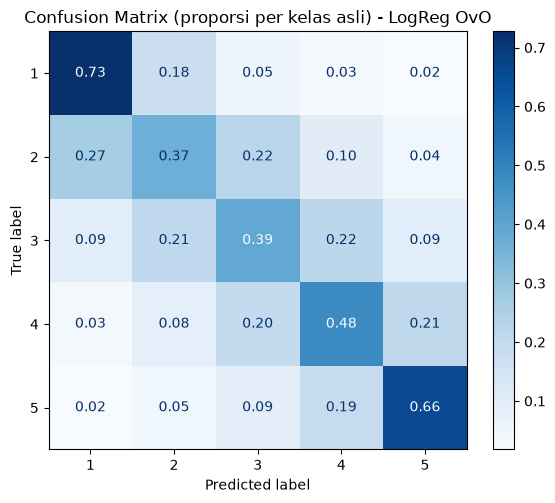

In [15]:
# Logistic Regression One-vs-One
pipe_ovo = build_pipeline(OneVsOneClassifier(logreg, n_jobs=-1), kind="linear")

mulai = time.time()
pipe_ovo.fit(X_tr, y_tr)
pred_ovo = pipe_ovo.predict(X_val)
print(f"Waktu: {time.time() - mulai:.0f} detik")

hasil_model.append(evaluate_model(y_val, pred_ovo, "LogReg OvO",
                                  FIGURE_DIR / "cm_logreg_ovo.png"))

Waktu: 191 detik
Random Forest | Macro F1: 0.5507 | Akurasi: 0.5808

              precision    recall  f1-score   support

           1      0.588     0.760     0.663     11034
           2      0.393     0.418     0.405     12216
           3      0.431     0.432     0.431     19098
           4      0.527     0.519     0.523     25738
           5      0.769     0.696     0.731     38607

    accuracy                          0.581    106693
   macro avg      0.542     0.565     0.551    106693
weighted avg      0.588     0.581     0.583    106693



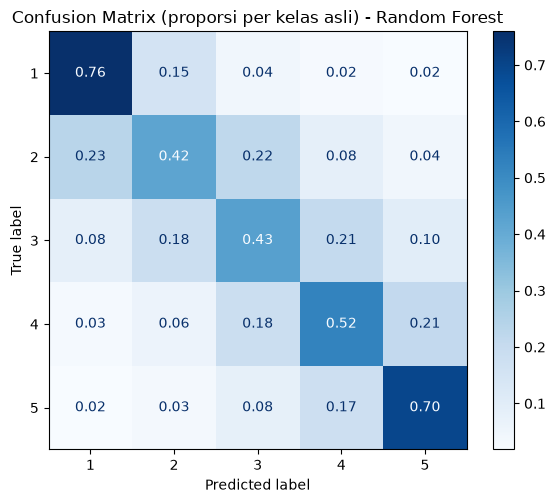

In [7]:
## 5. Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=150, max_depth=25, min_samples_leaf=3,
                            class_weight="balanced_subsample", n_jobs=-1,
                            random_state=RANDOM_STATE)
pipe_rf = build_pipeline(rf, kind="tree")

mulai = time.time()
pipe_rf.fit(X_tr, y_tr)
pred_rf = pipe_rf.predict(X_val)
print(f"Waktu: {time.time() - mulai:.0f} detik")

hasil_model.append(evaluate_model(y_val, pred_rf, "Random Forest",
                                  FIGURE_DIR / "cm_random_forest.png"))

Waktu: 240 detik
LightGBM | Macro F1: 0.5473 | Akurasi: 0.5737

              precision    recall  f1-score   support

           1      0.590     0.769     0.668     11034
           2      0.369     0.445     0.403     12216
           3      0.426     0.423     0.425     19098
           4      0.522     0.513     0.517     25738
           5      0.780     0.674     0.723     38607

    accuracy                          0.574    106693
   macro avg      0.538     0.565     0.547    106693
weighted avg      0.588     0.574     0.578    106693



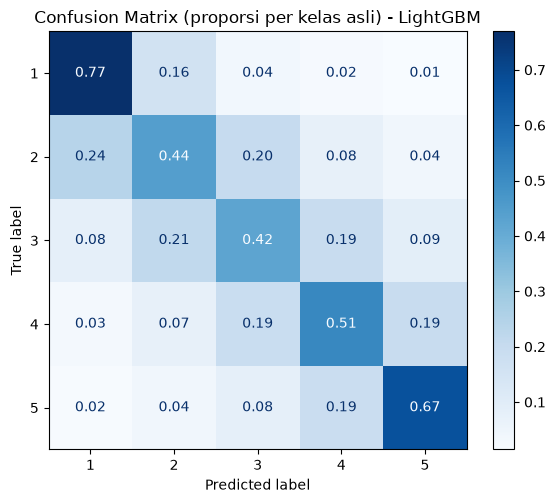

In [17]:
## 6. LightGBM
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(objective="multiclass", n_estimators=600, learning_rate=0.05,
                      num_leaves=127, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
pipe_lgbm = build_pipeline(lgbm, kind="tree")

mulai = time.time()
pipe_lgbm.fit(X_tr, y_tr)
pred_lgbm = pipe_lgbm.predict(X_val)
print(f"Waktu: {time.time() - mulai:.0f} detik")

hasil_model.append(evaluate_model(y_val, pred_lgbm, "LightGBM",
                                  FIGURE_DIR / "cm_lightgbm.png"))

,model,macro_f1,accuracy
0,Random Forest,0.5507,0.5808
1,LightGBM,0.5473,0.5737
2,LogReg OvO,0.5088,0.5408
3,LogReg OvR,0.5050,0.5441


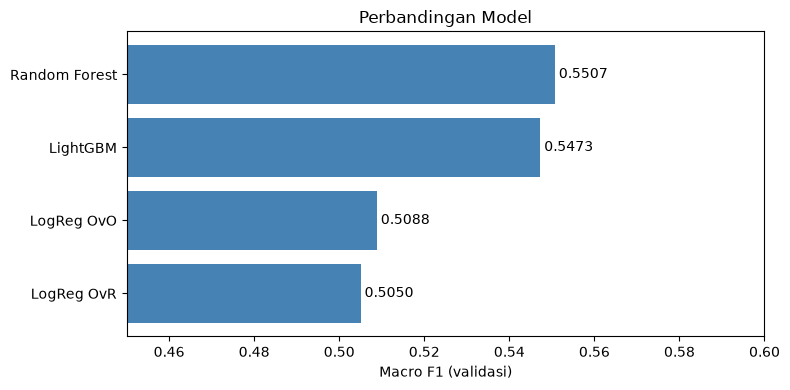

In [18]:
## 7. Perbandingan Model
# Tabel dan grafik perbandingan model
df_hasil = pd.DataFrame(hasil_model).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(df_hasil.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(df_hasil["model"], df_hasil["macro_f1"], color="steelblue")
for i, v in enumerate(df_hasil["macro_f1"]):
    ax.text(v, i, f" {v:.4f}", va="center")
ax.invert_yaxis()
ax.set_xlim(0.45, 0.6)
ax.set_xlabel("Macro F1 (validasi)")
ax.set_title("Perbandingan Model")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "perbandingan_model.png", dpi=150)
plt.show()

In [19]:
## 8. Tuning Hyperparameter (LightGBM) -> RandomizedSearchCV (15 kombinasi, StratifiedKFold 3-fold, metrik Macro F1)
# Randomized search hyperparameter LightGBM
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform, loguniform

X_tune, _, y_tune, _ = train_test_split(X_tr, y_tr, train_size=100_000,
                                        stratify=y_tr, random_state=RANDOM_STATE)

param_dist = {
    "model__num_leaves": randint(31, 256),
    "model__learning_rate": loguniform(0.02, 0.2),
    "model__n_estimators": randint(200, 800),
    "model__min_child_samples": randint(10, 100),
    "model__colsample_bytree": uniform(0.5, 0.5),
    "model__subsample": uniform(0.6, 0.4),
    "model__reg_lambda": loguniform(1e-3, 10),
}

lgbm_base = LGBMClassifier(objective="multiclass", subsample_freq=1, class_weight="balanced",
                           n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)

search = RandomizedSearchCV(
    build_pipeline(lgbm_base, kind="tree"), param_dist, n_iter=15, scoring="f1_macro",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1, random_state=RANDOM_STATE, verbose=1)

mulai = time.time()
search.fit(X_tune, y_tune)
print(f"Waktu: {(time.time() - mulai) / 60:.1f} menit")
print("Macro F1 CV terbaik:", round(search.best_score_, 4))
search.best_params_

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Waktu: 53.3 menit
Macro F1 CV terbaik: 0.5249


{'model__colsample_bytree': np.float64(0.5993578407670862),
 'model__learning_rate': np.float64(0.020255926514662966),
 'model__min_child_samples': 20,
 'model__n_estimators': 698,
 'model__num_leaves': 111,
 'model__reg_lambda': np.float64(0.7004349545230062),
 'model__subsample': np.float64(0.9160702162124823)}

Waktu: 396 detik
LightGBM Tuned | Macro F1: 0.5401 | Akurasi: 0.5668

              precision    recall  f1-score   support

           1      0.575     0.780     0.662     11034
           2      0.359     0.443     0.397     12216
           3      0.423     0.407     0.414     19098
           4      0.515     0.506     0.510     25738
           5      0.778     0.665     0.717     38607

    accuracy                          0.567    106693
   macro avg      0.530     0.560     0.540    106693
weighted avg      0.582     0.567     0.571    106693



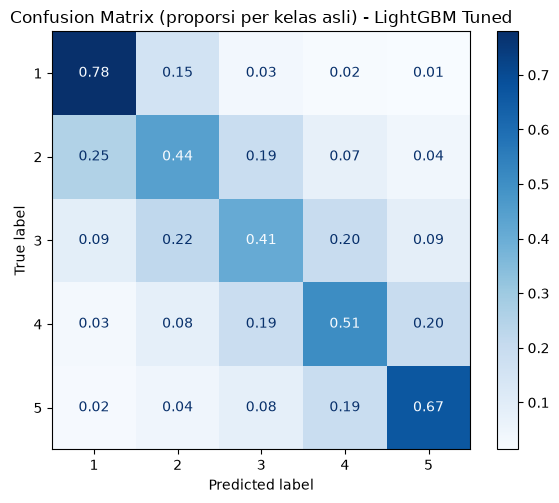

In [20]:
# Model terbaik dilatih ulang pada seluruh data latih
pipe_best = build_pipeline(lgbm_base, kind="tree").set_params(**search.best_params_)

mulai = time.time()
pipe_best.fit(X_tr, y_tr)
pred_best = pipe_best.predict(X_val)
print(f"Waktu: {time.time() - mulai:.0f} detik")

hasil_model.append(evaluate_model(y_val, pred_best, "LightGBM Tuned",
                                  FIGURE_DIR / "cm_lightgbm_tuned.png"))

**Insight tuning:**
- Parameter terbaik hasil RandomizedSearchCV (Macro F1 CV 0,5249 pada sampel 100.000 baris) menghasilkan Macro F1 validasi 0,5401, lebih rendah dibanding LightGBM parameter awal (0,5473).
- Penurunan diduga terjadi karena parameter optimal pada subsampel (learning rate 0,02, colsample 0,6) bersifat terlalu konservatif untuk data latih penuh sehingga model mengalami underfitting.
- Hasil tuning tidak digunakan; Random Forest dan LightGBM parameter awal dipertahankan sebagai kandidat model final.

In [21]:
def optimize_class_weights(proba, y_true, classes, grid=None, n_rounds=3):
    """
    Bobot per kelas pada probabilitas dicari untuk memaksimalkan Macro F1.

    Prediksi akhir ditentukan oleh argmax(proba × bobot). Pencarian dilakukan
    secara bergantian per kelas (coordinate search) sebanyak n_rounds putaran.

    Parameters
    ----------
    proba : np.ndarray, shape (n_sampel, n_kelas)
        Probabilitas prediksi.
    y_true : array-like
        Label sebenarnya.
    classes : np.ndarray
        Urutan label kelas sesuai kolom proba.
    grid : array-like, optional
        Kandidat nilai bobot. Default 0,5–2,0.
    n_rounds : int
        Jumlah putaran pencarian.

    Returns
    -------
    weights : np.ndarray
        Bobot terbaik per kelas.
    best_score : float
        Macro F1 dengan bobot terbaik.
    """
    grid = np.linspace(0.5, 2.0, 31) if grid is None else grid
    weights = np.ones(proba.shape[1])
    best_score = f1_score(y_true, classes[np.argmax(proba * weights, axis=1)], average="macro")

    for _ in range(n_rounds):
        for k in range(len(weights)):
            for g in grid:
                w_try = weights.copy()
                w_try[k] = g
                score = f1_score(y_true, classes[np.argmax(proba * w_try, axis=1)], average="macro")
                if score > best_score:
                    best_score, weights = score, w_try
    return weights, best_score

In [22]:
## 9. Ensemble dan Penyesuaian Bobot Kelas (Random Forest dan LightGBM)
# Probabilitas validasi dan ensemble soft voting
from sklearn.metrics import f1_score

proba_rf = pipe_rf.predict_proba(X_val)
proba_lgbm = pipe_lgbm.predict_proba(X_val)
proba_ens = (proba_rf + proba_lgbm) / 2
kelas = pipe_rf.classes_

for nama, p in [("Random Forest", proba_rf), ("LightGBM", proba_lgbm), ("Ensemble RF+LGBM", proba_ens)]:
    print(f"{nama:17} | Macro F1: {f1_score(y_val, kelas[p.argmax(1)], average='macro'):.4f}")


Random Forest     | Macro F1: 0.5507
LightGBM          | Macro F1: 0.5473
Ensemble RF+LGBM  | Macro F1: 0.5512


In [25]:
import importlib, scripts.evaluate
importlib.reload(scripts.evaluate) 

# Optimasi bobot kelas: dicari pada bagian A, dievaluasi pada bagian B
from scripts.evaluate import optimize_class_weights

idx_a, idx_b = train_test_split(np.arange(len(y_val)), test_size=0.5,
                                stratify=y_val, random_state=RANDOM_STATE)
y_val_arr = y_val.to_numpy()

for nama, p in [("Random Forest", proba_rf), ("Ensemble RF+LGBM", proba_ens)]:
    bobot, skor_a = optimize_class_weights(p[idx_a], y_val_arr[idx_a], kelas)
    sebelum_b = f1_score(y_val_arr[idx_b], kelas[p[idx_b].argmax(1)], average="macro")
    sesudah_b = f1_score(y_val_arr[idx_b], kelas[(p[idx_b] * bobot).argmax(1)], average="macro")
    print(f"{nama:17} | bobot: {np.round(bobot, 2)} | B sebelum: {sebelum_b:.4f} | B sesudah: {sesudah_b:.4f}")

Random Forest     | bobot: [0.65 0.95 1.   1.   0.95] | B sebelum: 0.5478 | B sesudah: 0.5527
Ensemble RF+LGBM  | bobot: [0.5  0.9  1.   1.05 1.05] | B sebelum: 0.5491 | B sesudah: 0.5550


In [27]:
## 10. Model Final (ensemble RF + LightGBM dengan bobot kelas)
# Pelatihan model final pada seluruh data train
import joblib
from scripts.train import build_final_model
importlib.reload(scripts.train)  
from scripts.train import build_final_model

bobot_final = [0.5, 0.9, 1.0, 1.05, 1.05]
final_model = build_final_model(rf, lgbm, bobot_final)

mulai = time.time()
final_model.fit(X, y)
print(f"Waktu: {(time.time() - mulai) / 60:.1f} menit")

joblib.dump(final_model, MODEL_PATH, compress=3)
print("Model disimpan:", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.0f} MB)")


Waktu: 9.8 menit
Model disimpan: C:\Users\zerohack\Documents\Structural-Damage-Classification\models\pipeline_model.pkl (1233 MB)


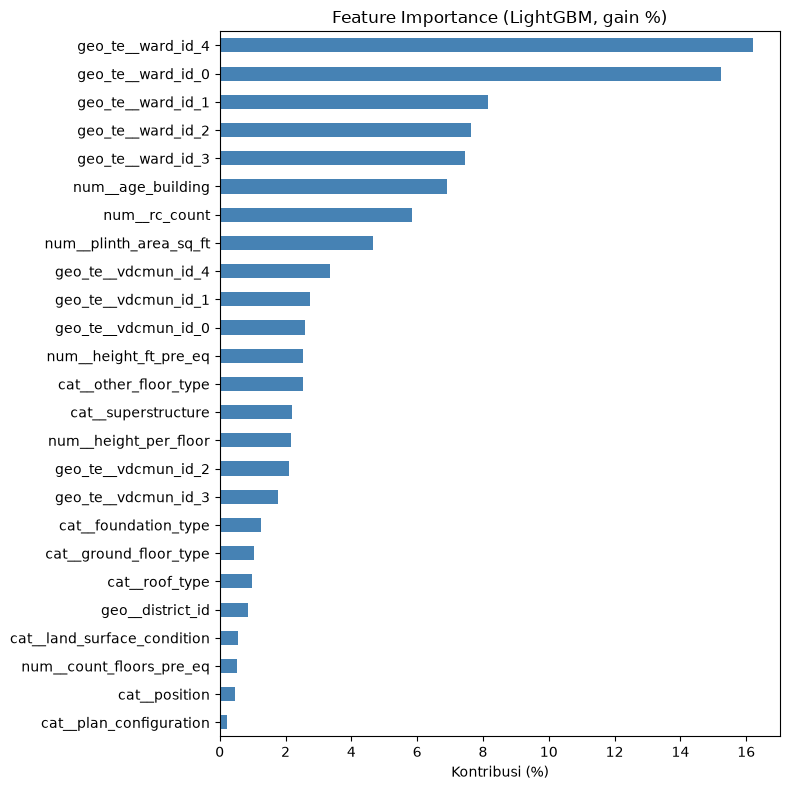

lokasi       68.1
numerik      22.6
kategorik     9.3
dtype: float64

In [29]:
# Feature importance LightGBM (gain) pada model final
lgbm_final = final_model.estimator_.named_estimators_["lgbm"]
nama = lgbm_final.named_steps["preprocess"].get_feature_names_out()
gain = lgbm_final.named_steps["model"].booster_.feature_importance(importance_type="gain")
imp = pd.Series(gain, index=nama)
imp = (imp / imp.sum() * 100).sort_values()   # dinyatakan dalam persen

fig, ax = plt.subplots(figsize=(8, 8))
imp.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Feature Importance (LightGBM, gain %)")
ax.set_xlabel("Kontribusi (%)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "feature_importance.png", dpi=150)
plt.show()

# Kontribusi per kelompok fitur
kelompok = imp.groupby(lambda n: "lokasi" if "geo" in n else ("numerik" if n.startswith("num") else "kategorik")).sum()
kelompok.sort_values(ascending=False).round(1)

In [8]:
# Persiapan eksperimen
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score
from scripts.evaluate import optimize_class_weights

proba_rf = pipe_rf.predict_proba(X_val)
kelas = pipe_rf.classes_
y_val_arr = y_val.to_numpy()
idx_a, idx_b = train_test_split(np.arange(len(y_val)), test_size=0.5,
                                stratify=y_val, random_state=RANDOM_STATE)
print("Siap | proba_rf:", proba_rf.shape)

Siap | proba_rf: (106693, 5)


In [9]:
#11. Eksperimen Lanjutan: LightGBM dengan Early Stopping 
#LightGBM dilatih ulang tanpa `class_weight` dengan kapasitas lebih besar (`num_leaves=255`)
# Preprocessing di-fit terpisah agar early stopping dapat digunakan
from lightgbm import early_stopping, log_evaluation

prep = build_pipeline("passthrough", kind="tree")
Xt_tr = prep.fit_transform(X_tr, y_tr)
Xt_val = prep.transform(X_val)

lgbm_es = LGBMClassifier(objective="multiclass", n_estimators=2000, learning_rate=0.06,
                         num_leaves=255, min_child_samples=50, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.7, reg_lambda=1.0,
                         n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)

mulai = time.time()
lgbm_es.fit(Xt_tr, y_tr,
            eval_set=[(Xt_val[idx_a], y_val_arr[idx_a])],
            callbacks=[early_stopping(100), log_evaluation(100)])
print(f"Waktu: {(time.time() - mulai) / 60:.1f} menit | iterasi terbaik: {lgbm_es.best_iteration_}")

Training until validation scores don't improve for 100 rounds
[100]	valid_0's multi_logloss: 0.983224
[200]	valid_0's multi_logloss: 0.972121
[300]	valid_0's multi_logloss: 0.968031
[400]	valid_0's multi_logloss: 0.96682
Early stopping, best iteration is:
[391]	valid_0's multi_logloss: 0.966667
Waktu: 2.7 menit | iterasi terbaik: 391


In [10]:
# Perbandingan pada validasi bagian B (bobot dicari pada bagian A)
proba_es = lgbm_es.predict_proba(Xt_val)
proba_ens2 = (proba_rf + proba_es) / 2

for nama, p in [("LGBM early stop", proba_es), ("Ensemble RF+LGBM ES", proba_ens2)]:
    bobot, _ = optimize_class_weights(p[idx_a], y_val_arr[idx_a], kelas)
    sebelum_b = f1_score(y_val_arr[idx_b], kelas[p[idx_b].argmax(1)], average="macro")
    sesudah_b = f1_score(y_val_arr[idx_b], kelas[(p[idx_b] * bobot).argmax(1)], average="macro")
    print(f"{nama:20} | bobot: {np.round(bobot, 2)} | B sebelum: {sebelum_b:.4f} | B sesudah: {sesudah_b:.4f}")

print("\nPembanding model final saat ini (B sesudah bobot): 0.5550")

LGBM early stop      | bobot: [0.8  1.2  1.05 1.   0.7 ] | B sebelum: 0.5456 | B sesudah: 0.5518
Ensemble RF+LGBM ES  | bobot: [0.8  1.1  1.05 1.   0.8 ] | B sebelum: 0.5510 | B sesudah: 0.5563

Pembanding model final saat ini (B sesudah bobot): 0.5550


In [11]:
# Model final v2: RF + LightGBM early stopping dengan bobot kelas baru
lgbm_v2 = LGBMClassifier(objective="multiclass", n_estimators=430, learning_rate=0.06,
                         num_leaves=255, min_child_samples=50, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.7, reg_lambda=1.0,
                         n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
bobot_v2 = [0.8, 1.1, 1.05, 1.0, 0.8]

import joblib
from scripts.train import build_final_model

final_v2 = build_final_model(rf, lgbm_v2, bobot_v2)

mulai = time.time()
final_v2.fit(X, y)
print(f"Waktu: {(time.time() - mulai) / 60:.1f} menit")

MODEL_V2_PATH = MODEL_DIR / "pipeline_model_v2.pkl"
joblib.dump(final_v2, MODEL_V2_PATH, compress=3)
print("Model disimpan:", MODEL_V2_PATH)

Waktu: 5.7 menit
Model disimpan: C:\Users\zerohack\Documents\Structural-Damage-Classification\models\pipeline_model_v2.pkl


In [13]:
# 11.2 Eksperimen Fitur Konteks Wilayah
#Rata-rata umur, `rc_count`, jumlah lantai, dan luas bangunan serta jumlah bangunan per `ward_id` dan `vdcmun_id` ditambahkan sebagai fitur konteks. 
# Eksperimen LightGBM dengan fitur konteks wilayah
import importlib, scripts.feature_engineering, scripts.preprocess, scripts.train
for m in [scripts.feature_engineering, scripts.preprocess, scripts.train]:
    importlib.reload(m)
from scripts.train import build_pipeline

prep_agg = build_pipeline("passthrough", kind="tree", aggregate=True)
Xa_tr = prep_agg.fit_transform(X_tr, y_tr)
Xa_val = prep_agg.transform(X_val)
print("Jumlah fitur:", Xa_tr.shape[1])

lgbm_agg = LGBMClassifier(objective="multiclass", n_estimators=2000, learning_rate=0.06,
                          num_leaves=255, min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.7, reg_lambda=1.0,
                          n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)

mulai = time.time()
lgbm_agg.fit(Xa_tr, y_tr, eval_set=[(Xa_val[idx_a], y_val_arr[idx_a])],
             callbacks=[early_stopping(100), log_evaluation(100)])
print(f"Waktu: {(time.time() - mulai) / 60:.1f} menit | iterasi terbaik: {lgbm_agg.best_iteration_}")

Jumlah fitur: 35
Training until validation scores don't improve for 100 rounds
[100]	valid_0's multi_logloss: 0.976425
[200]	valid_0's multi_logloss: 0.96582
[300]	valid_0's multi_logloss: 0.96255
[400]	valid_0's multi_logloss: 0.962407
Early stopping, best iteration is:
[390]	valid_0's multi_logloss: 0.962235
Waktu: 6.3 menit | iterasi terbaik: 390


In [14]:
# Perbandingan pada validasi bagian B
proba_agg = lgbm_agg.predict_proba(Xa_val)
proba_ens3 = (proba_rf + proba_agg) / 2

for nama, p in [("LGBM + agregat", proba_agg), ("Ensemble RF+LGBM agregat", proba_ens3)]:
    bobot, _ = optimize_class_weights(p[idx_a], y_val_arr[idx_a], kelas)
    sebelum_b = f1_score(y_val_arr[idx_b], kelas[p[idx_b].argmax(1)], average="macro")
    sesudah_b = f1_score(y_val_arr[idx_b], kelas[(p[idx_b] * bobot).argmax(1)], average="macro")
    print(f"{nama:25} | bobot: {np.round(bobot, 2)} | B sebelum: {sebelum_b:.4f} | B sesudah: {sesudah_b:.4f}")

print("\nPembanding v2 (B sesudah bobot): 0.5563 | target minimal: 0.5593")

LGBM + agregat            | bobot: [0.85 1.2  1.15 1.05 0.7 ] | B sebelum: 0.5459 | B sesudah: 0.5532
Ensemble RF+LGBM agregat  | bobot: [0.9 1.2 1.1 1.  0.8] | B sebelum: 0.5508 | B sesudah: 0.5563

Pembanding v2 (B sesudah bobot): 0.5563 | target minimal: 0.5593


In [16]:
MODEL_PATH = MODEL_DIR / "pipeline_model_v2.pkl"   # model final terpilih